In [19]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Model, layers
from tensorflow.keras.datasets import mnist


In [20]:
# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize pixel values to the range 0 to 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten each 28 x 28 image into a vector of 784 features
x_train = x_train.reshape((-1, 784))
x_test = x_test.reshape((-1, 784))

# Use only digit 0 images to train the autoencoder (normal samples)
x_train_normal = x_train[y_train == 0]

print("Normal training samples:", x_train_normal.shape)
print("Test samples:", x_test.shape)

# Define test labels: 0 = normal digit 0, 1 = anomaly (other digits)
y_test_anomaly = (y_test != 0).astype("int32")
print("Normal test samples:", np.sum(y_test_anomaly == 0))
print("Anomalous test samples:", np.sum(y_test_anomaly == 1))

Normal training samples: (5923, 784)
Test samples: (10000, 784)
Normal test samples: 980
Anomalous test samples: 9020


In [21]:
input_dim = 784
latent_dim = 32

# Encoder maps 784 input values into a 32-dimensional latent vector
encoder_input = layers.Input(shape=(input_dim,), name="encoder_input")
x = layers.Dense(128, activation="relu")(encoder_input)
x = layers.Dense(64, activation="relu")(x)
latent_vector = layers.Dense(latent_dim, activation="relu", name="latent_vector")(x)

encoder = Model(encoder_input, latent_vector, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# Decoder maps the 32-dimensional latent vector back to 784 values
decoder_input = layers.Input(shape=(latent_dim,), name="decoder_input")
x = layers.Dense(64, activation="relu")(decoder_input)
x = layers.Dense(128, activation="relu")(x)
reconstructed_output = layers.Dense(input_dim, activation="sigmoid")(x)

decoder = Model(decoder_input, reconstructed_output, name="decoder")
decoder.summary()

# Combine encoder and decoder into one autoencoder
autoencoder_input = layers.Input(shape=(input_dim,), name="autoencoder_input")
encoded = encoder(autoencoder_input)
decoded = decoder(encoded)
autoencoder = Model(autoencoder_input, decoded, name="autoencoder")

autoencoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Optimizer: Adam; Loss: mean squared error (MSE)
# Metric: mean absolute error (MAE)
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

history = autoencoder.fit(
    x_train_normal,
    x_train_normal,          # Target is the same input image
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.1065 - mae: 0.2257 - val_loss: 0.0631 - val_mae: 0.1327
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0565 - mae: 0.1245 - val_loss: 0.0492 - val_mae: 0.1138
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0438 - mae: 0.1038 - val_loss: 0.0384 - val_mae: 0.0939
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0370 - mae: 0.0916 - val_loss: 0.0335 - val_mae: 0.0836
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0326 - mae: 0.0827 - val_loss: 0.0303 - val_mae: 0.0781
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0292 - mae: 0.0766 - val_loss: 0.0267 - val_mae: 0.0714
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0257 - mae: 0.0696 - val_loss: 0.0241 - val_mae: 0.0659
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0235 - mae: 0.0647 - val_loss: 0.0221 - val_mae: 0.0619
Epoch 9/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.021

In [24]:
# Evaluate reconstruction quality on the complete test set
test_loss, test_mae = autoencoder.evaluate(x_test, x_test, verbose=0)
print(f"Test reconstruction loss (MSE): {test_loss}")
print(f"Test reconstruction MAE: {test_mae}")

# Reconstruction error for each test image (mean squared error per image)
x_test_reconstructed = autoencoder.predict(x_test, verbose=0)
reconstruction_error = np.mean(np.square(x_test - x_test_reconstructed), axis=1)

# Select a threshold using the 95th percentile of training-normal errors
normal_reconstructed = autoencoder.predict(x_train_normal, verbose=0)
normal_error = np.mean(np.square(x_train_normal - normal_reconstructed), axis=1)
threshold = np.percentile(normal_error, 95)

# Error above threshold => anomaly
y_pred_anomaly = (reconstruction_error > threshold).astype("int32")

print(f"Anomaly threshold: {threshold:.6f}")
print(f"Detected anomalies: {np.sum(y_pred_anomaly == 1)} out of {len(y_pred_anomaly)} test images")

# Basic metrics
true_positive = np.sum((y_pred_anomaly == 1) & (y_test_anomaly == 1))
true_negative = np.sum((y_pred_anomaly == 0) & (y_test_anomaly == 0))
false_positive = np.sum((y_pred_anomaly == 1) & (y_test_anomaly == 0))
false_negative = np.sum((y_pred_anomaly == 0) & (y_test_anomaly == 1))

accuracy = (true_positive + true_negative) / len(y_test_anomaly)
precision = true_positive / (true_positive + false_positive + 1e-8)
recall = true_positive / (true_positive + false_negative + 1e-8)

print(f"Detection accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Test reconstruction loss (MSE): 0.06781598180532455
Test reconstruction MAE: 0.14502470195293427
Anomaly threshold: 0.036502
Detected anomalies: 8970 out of 10000 test images
Detection accuracy: 98.48%
Precision: 0.9943
Recall: 0.9888


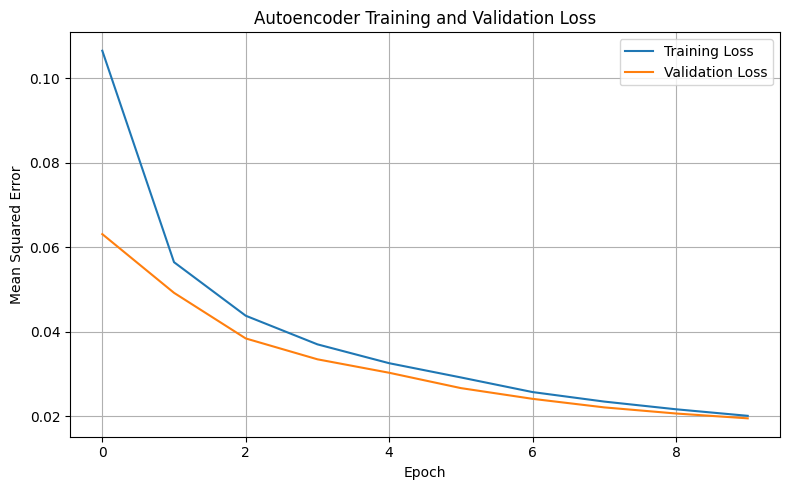

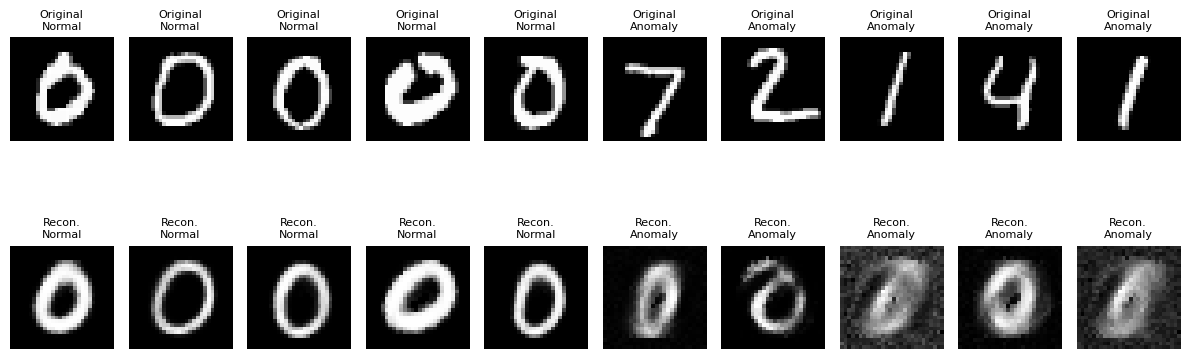

In [25]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Display examples of normal and anomalous test samples
sample_indices = []
for wanted_label in [0, 1]:
    candidates = np.where(y_test_anomaly == wanted_label)[0]
    if len(candidates):
        sample_indices.extend(candidates[:5].tolist())

plt.figure(figsize=(12, 5))
for position, idx in enumerate(sample_indices):
    # Original image
    plt.subplot(2, 10, position + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap="gray")
    plt.title("Original\n" + ("Anomaly" if y_test_anomaly[idx] else "Normal"), fontsize=8)
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, position + 11)
    plt.imshow(x_test_reconstructed[idx].reshape(28, 28), cmap="gray")
    detected = "Anomaly" if y_pred_anomaly[idx] else "Normal"
    plt.title(f"Recon.\n{detected}", fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()